## ДЗ №2. Матричные факторизации

#### В этой домашке вам предстоит реализовать некоторые базовые модели матричной факторизации

#### Дата выдачи: 17.02.25

#### Мягкий дедлайн: 02.03.25 23:59 MSK

#### Жесткий дедлайн: 09.03.25 23:59 MSK

В этом задании мы будем работать с классическим для рекоендательных систем датасетом [MovieLens 1M](https://grouplens.org/datasets/movielens/1m/). Датасет содержит рейтинги оценки для 4000 фильмов от 6000 пользователей. Более подробное описание можете найти на странице с датасетом и в README файле

In [1]:
# аналог !wget https://files.grouplens.org/datasets/movielens/ml-1m.zip && !unzip ml-1m.zip — данные кладём в data/ml-1m
import os, urllib.request, zipfile
DATA_DIR = os.path.join('data', 'ml-1m')
if not os.path.exists(os.path.join(DATA_DIR, 'ratings.dat')):
    os.makedirs('data', exist_ok=True)
    urllib.request.urlretrieve('https://files.grouplens.org/datasets/movielens/ml-1m.zip', 'data/ml-1m.zip')
    zipfile.ZipFile('data/ml-1m.zip').extractall('data')
print(os.listdir(DATA_DIR))
print(open(os.path.join(DATA_DIR, 'README'), encoding='latin-1').read()[:2000])

['movies.dat', 'ratings.dat', 'README', 'users.dat']
SUMMARY

These files contain 1,000,209 anonymous ratings of approximately 3,900 movies 
made by 6,040 MovieLens users who joined MovieLens in 2000.

USAGE LICENSE

Neither the University of Minnesota nor any of the researchers
involved can guarantee the correctness of the data, its suitability
for any particular purpose, or the validity of results based on the
use of the data set.  The data set may be used for any research
purposes under the following conditions:

     * The user may not state or imply any endorsement from the
       University of Minnesota or the GroupLens Research Group.

     * The user must acknowledge the use of the data set in
       publications resulting from the use of the data set
       (see below for citation information).

     * The user may not redistribute the data without separate
       permission.

     * The user may not use this information for any commercial or
       revenue-bearing purposes wi

In [2]:
import pandas as pd
import numpy as np
from typing import Union
import time
%matplotlib inline
import warnings
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

warnings.filterwarnings('ignore')
np.random.seed(42)

In [3]:
df = pd.read_csv(os.path.join(DATA_DIR, "ratings.dat"), sep='::', names=['user_id', 'item_id', 'rating', 'timestamp'], engine='python')
df['datetime'] = pd.to_datetime(df['timestamp'], unit='s')
df.drop('timestamp', axis=1, inplace=True)
df.head()

,user_id,item_id,rating,datetime
0,1,1193,5,2000-12-31 22:12:40
1,1,661,3,2000-12-31 22:35:09
2,1,914,3,2000-12-31 22:32:48
3,1,3408,4,2000-12-31 22:04:35
4,1,2355,5,2001-01-06 23:38:11


In [4]:
value_counts = df['item_id'].value_counts()
filtered_values = value_counts[value_counts > 20].index
df = df[df['item_id'].isin(filtered_values)].copy()

In [5]:
train_end = '2000-12-01'
df_train = df[df['datetime'] < train_end].copy()
df_test = df[df['datetime'] >= train_end].copy()
df_train.shape, df_test.shape

((787420, 4), (207432, 4))

In [6]:
train_users = df_train['user_id'].unique()
train_items = df_train['item_id'].unique()

df_test = df_test[df_test['user_id'].isin(train_users)]
df_test = df_test[df_test['item_id'].isin(train_items)]
df_test.shape

(106471, 4)

In [7]:
from sklearn.preprocessing import LabelEncoder

user_le = LabelEncoder()
item_le = LabelEncoder()

df_train['user_id'] = user_le.fit_transform(df_train['user_id'])
df_train['item_id'] = item_le.fit_transform(df_train['item_id'])

df_test['user_id'] = user_le.transform(df_test['user_id'])
df_test['item_id'] = item_le.transform(df_test['item_id'])

In [8]:
print(df_train['user_id'].nunique(), df_train['user_id'].max())
print(df_train['item_id'].nunique(), df_train['item_id'].max())

5365 5364
3010 3009


##### Задание 1. Напишем функцию, которая превратит датафрейм в матрицу интеракций. В функции df_to_matrix реализуйте функцию, которая принимает датафрейм и возвращает np.array матрицу интеракций. В функции df_to_coo реализуйте функцию, которая принимает датафрейм и возвращает разреженную матрицу интеракций в coo_array формате

In [9]:
N_USERS = len(user_le.classes_)
N_ITEMS = len(item_le.classes_)

def df_to_matrix(df: pd.DataFrame) -> np.ndarray:
    # строки — пользователи, столбцы — айтемы, значение — рейтинг (0 — нет взаимодействия)
    result = np.zeros((N_USERS, N_ITEMS), dtype=np.float64)
    result[df['user_id'].values, df['item_id'].values] = df['rating'].values
    return result #shape ~ [n_users, n_items]

In [10]:
interactions = df_to_matrix(df_train)

In [11]:
from scipy.sparse import coo_array

def df_to_coo(df: pd.DataFrame) -> coo_array:
    result = coo_array(
        (df['rating'].values.astype(np.float64), (df['user_id'].values, df['item_id'].values)),
        shape=(N_USERS, N_ITEMS),
    )
    return result # coo_array

In [12]:
coo_interactions = df_to_coo(df_train)

In [13]:
assert (interactions != 0).sum() == df_train.shape[0]
assert interactions[0, 2994] == 3
assert interactions[2369, 1203] == 5
assert interactions[1557, 459] == 3
assert np.allclose(coo_interactions.toarray(), interactions)

##### Задание 2.1. Рассмотрим [SVD](https://en.wikipedia.org/wiki/Singular_value_decomposition). Возьмите готовую реализуцию алгоритма из numpy.linalg или из scipy.linalg и примените алгоритм к матрицам интеракций, полученным в первом задании. Для работы со sparse матрицей обычная реализация svd не подойдет и нужно будет воспользоваться scipy.sparse.linalg.svds. Вам нужно разложить матрицу интеракций на 3 матрицы U, S, V, а затем перемножить их и восстановить изначальную матрицу. При полном разложении исходная матрица должна восстанавливаться максимально хорошо

In [14]:
from scipy.sparse import issparse
from scipy.sparse.linalg import svds

def make_svd(interractions: Union[np.ndarray, coo_array], n_singular_values: int = -1):
    # функция должна работать и для полной матрицы и для sparse матрицы(вам поможет isinstance).
    # если n_singular_values = -1, то берем все сингулярные числа для полной матрицы
    # и все кроме одного сингулярного числа для coo-матрицы(иначе scipy.sparse.linalg.svds не будет работать)
    if isinstance(interractions, np.ndarray):
        U, s, V = np.linalg.svd(interractions, full_matrices=False)
        if n_singular_values != -1:
            U, s, V = U[:, :n_singular_values], s[:n_singular_values], V[:n_singular_values, :]
    else:
        matrix = interractions.tocsr().astype(np.float64)
        k = min(matrix.shape) - 1 if n_singular_values == -1 else n_singular_values
        U, s, V = svds(matrix, k=k, v0=np.full(min(matrix.shape), 1 / np.sqrt(min(matrix.shape))))   # фиксированный стартовый вектор — воспроизводимо
        # svds возвращает сингулярные числа по возрастанию — упорядочим по убыванию, как в np.linalg.svd
        order = np.argsort(s)[::-1]
        U, s, V = U[:, order], s[order], V[order, :]
    S = np.diag(s)
    return U, S, V

In [15]:
U, S, V = make_svd(interactions)
assert np.allclose(U @ S @ V, interactions)

In [16]:
U1, S1, V1 = make_svd(interactions, 10)
U, S, V = make_svd(coo_interactions, 10)
assert np.allclose(U1 @ S1 @ V1, U @ S @ V)

Все проверки из шаблона для заданий 1 и 2.1 проходят: восстановление полной матрицы через SVD точное, а dense- и sparse-разложения с 10 сингулярными числами дают одинаковую матрицу.

##### Задание 2.2. Теперь попробуем сделать рекомендации с помощью SVD. Мы научились восстанавливать исходную матрицу с помощью разложения, теперь же мы хотим порекомендовать пользователю айтемы, которые будут для него максимально релевантны(в восстановленной матрице у них будет самый высокий скор). Для каждого пользователя нужно будет найти индексы айтемов, которые имеют максимальный скор. При этом стоит обратить внимание, что мы не хотим рекомендовать пользователю айтемы, с которыми он уже взаимодействовал

In [17]:
def _to_dense(interractions):
    return interractions if isinstance(interractions, np.ndarray) else interractions.toarray()


def top_k_from_scores(scores: np.ndarray, seen_mask: np.ndarray, top_k: int) -> np.ndarray:
    """Индексы top_k айтемов с максимальным скором для каждой строки, уже просмотренные исключаются."""
    scores = scores.astype(np.float64, copy=True)
    scores[seen_mask] = -np.inf
    idx = np.argpartition(-scores, top_k, axis=1)[:, :top_k]
    part = np.take_along_axis(scores, idx, axis=1)
    order = np.argsort(-part, axis=1)
    return np.take_along_axis(idx, order, axis=1)


def make_svd_recommendations(interractions: Union[np.ndarray, coo_array], n_singular_values: int = -1, top_k: int = 100,
                             seen_mask: np.ndarray = None):
    # Возвращает матрицу вида n_users, top_k, то есть для каждого пользователя возвращаем индексы
    # top_k самых релевантный айтемов среди тех с которыми он еще не взаимодействовал
    U, S, V = make_svd(interractions, n_singular_values)
    scores = (U @ S) @ V                      # восстановленная матрица
    if seen_mask is None:                     # по умолчанию «просмотренные» = ненулевые элементы исходной матрицы
        seen_mask = _to_dense(interractions) != 0
    recommendations = top_k_from_scores(scores, seen_mask, top_k)
    return recommendations #shape ~ [n_users, top_k]

In [18]:
# Метрики для оценки на тесте: NDCG@k и Recall@k с бинарной релевантностью
# (релевантны все фильмы, которые пользователь оценил в тестовом периоде)
test_gt = df_test.groupby('user_id')['item_id'].apply(list)
test_users = test_gt.index.values
print('Пользователей в тесте:', len(test_users), '| взаимодействий:', len(df_test))

def ndcg_at_k(gt_items, predicted, k=100):
    predicted = np.asarray(predicted)[:k]
    rel = np.isin(predicted, gt_items).astype(float)
    discounts = 1 / np.log2(np.arange(2, len(predicted) + 2))
    dcg = (rel * discounts).sum()
    idcg = discounts[:min(len(gt_items), k)].sum()
    return dcg / idcg if idcg > 0 else 0.0

def recall_at_k(gt_items, predicted, k=100):
    return np.isin(np.asarray(predicted)[:k], gt_items).sum() / len(gt_items)

def evaluate_recs(recs: np.ndarray, k: int = 100) -> dict:
    """recs — матрица [n_users, >=k] с индексами айтемов, оцениваем только пользователей из теста."""
    ndcgs = [ndcg_at_k(test_gt[u], recs[u], k) for u in test_users]
    recalls = [recall_at_k(test_gt[u], recs[u], k) for u in test_users]
    return {f'ndcg@{k}': np.mean(ndcgs), f'recall@{k}': np.mean(recalls)}

# бейзлайн для понимания масштаба метрик — популярное среди непросмотренного
pop_scores = np.tile((interactions != 0).sum(axis=0).astype(float), (N_USERS, 1))
pop_recs = top_k_from_scores(pop_scores, interactions != 0, 100)
print('TopPopular:', evaluate_recs(pop_recs))

Пользователей в тесте: 1147 | взаимодействий: 106471


TopPopular: {'ndcg@100': np.float64(0.25020199510420477), 'recall@100': np.float64(0.22740434846445978)}


In [19]:
# в шаблоне в этой ячейке опечатка: переменной interractions нет — используем матрицу interactions из задания 1
interractions = interactions
recs = make_svd_recommendations(interractions, -1, 100)
assert recs.shape == (interractions.shape[0], 100)

##### Задание 2.3. Теперь давайте посмотрим как будет зависеть качетво рекомендаций, от количества сингулярных чисел, которые мы возьмем в SVD разложении. Переберите n_singular_values из списка [1, 10, 50, 200, 1000] и посмотрите как будет изменяться метрика NDCG на тестовом датасете для таких рекомендаций и как будет меняться время вычисления. Для каждого графики зависимости метрики NDCG от n_singular_values и времени работы алгоритма от n_singular_values(Время работы будет меняться только для sparse-матрицы, стоит запускать алгоритм именно для нее)

In [20]:
def plot_graphs(interractions: Union[np.ndarray, coo_array], top_k: int = 100):
    results = []
    seen_mask = _to_dense(interractions) != 0
    for n_singular_values in [1, 10, 50, 200, 1000]:
        start = time.perf_counter()
        recs = make_svd_recommendations(interractions, n_singular_values, top_k, seen_mask=seen_mask)
        elapsed = time.perf_counter() - start
        metrics = evaluate_recs(recs, k=top_k)
        results.append({'n_singular_values': n_singular_values, 'time_sec': elapsed, **metrics})
        print(results[-1])
    results = pd.DataFrame(results)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].plot(results['n_singular_values'], results[f'ndcg@{top_k}'], marker='o')
    axes[0].set_xscale('log'); axes[0].set_xlabel('n_singular_values'); axes[0].set_ylabel(f'NDCG@{top_k}')
    axes[0].set_title('Качество SVD-рекомендаций'); axes[0].grid(alpha=0.3)
    axes[1].plot(results['n_singular_values'], results['time_sec'], marker='o', color='tab:orange')
    axes[1].set_xscale('log'); axes[1].set_xlabel('n_singular_values'); axes[1].set_ylabel('время, с')
    axes[1].set_title('Время svds + рекомендаций (sparse)'); axes[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()
    return results

{'n_singular_values': 1, 'time_sec': 0.20967416698113084, 'ndcg@100': np.float64(0.2426738132306059), 'recall@100': np.float64(0.21155222228447232)}


{'n_singular_values': 10, 'time_sec': 0.20763862505555153, 'ndcg@100': np.float64(0.2753986031099354), 'recall@100': np.float64(0.2583784105921062)}


{'n_singular_values': 50, 'time_sec': 0.3949432499939576, 'ndcg@100': np.float64(0.2535021839464003), 'recall@100': np.float64(0.24627594021498583)}


{'n_singular_values': 200, 'time_sec': 1.0709952500183135, 'ndcg@100': np.float64(0.19341888412788702), 'recall@100': np.float64(0.18299551293344127)}


{'n_singular_values': 1000, 'time_sec': 8.588295041001402, 'ndcg@100': np.float64(0.07383990474341957), 'recall@100': np.float64(0.06206485070111746)}


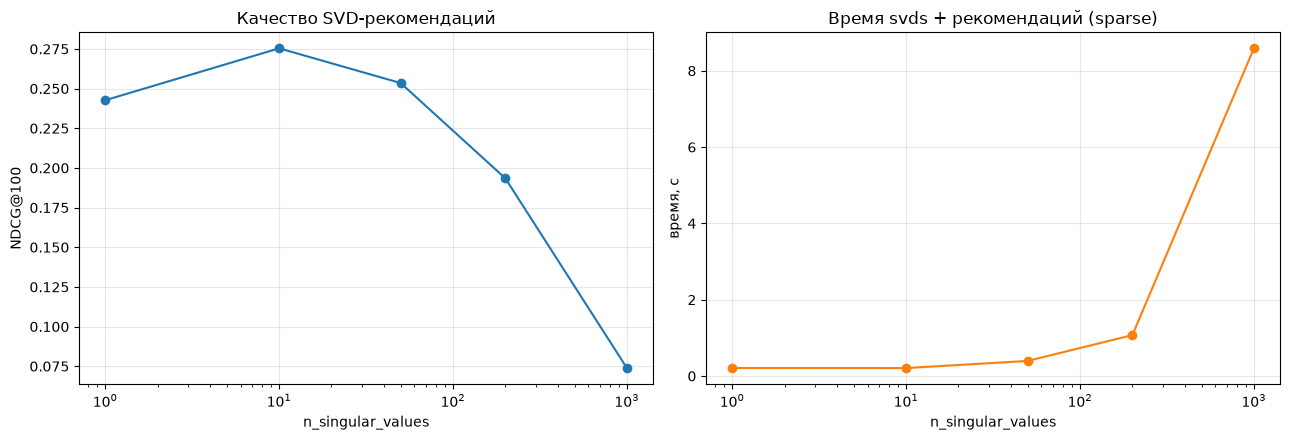

,n_singular_values,time_sec,ndcg@100,recall@100
0,1,0.209674,0.242674,0.211552
1,10,0.207639,0.275399,0.258378
2,50,0.394943,0.253502,0.246276
3,200,1.070995,0.193419,0.182996
4,1000,8.588295,0.073840,0.062065


In [21]:
svd_results = plot_graphs(coo_interactions, top_k=100)
svd_results

**Выводы (2.3).**
* **Качество** зависит от числа сингулярных чисел немонотонно. NDCG@100: 1 → 0.243, **10 → 0.275** (максимум; уточняющая сетка даёт 0.270–0.275 для 5–15), 50 → 0.254, 200 → 0.193, 1000 → 0.074. Для сравнения, у TopPopular 0.250.
* **Почему так.** Немного компонент описывают общие предпочтения — популярность и крупные «оси вкуса» — и хорошо обобщаются на непросмотренные фильмы. С ростом k разложение всё точнее восстанавливает конкретные наблюдённые оценки вместе с шумом, а скоры непросмотренных фильмов стремятся к нулю. При полном разложении матрица восстанавливается точно, и ранжирование непросмотренного становится произвольным.
* **Время** `svds` растёт сверхлинейно: ≈0.2 с при k ≤ 10, ≈1 с при k = 200, ≈9 с при k = 1000. Стоимость ARPACK растёт примерно как O(nnz·k + (m + n)·k²), плюс восстановление плотной матрицы U·S·V.

In [22]:
# Уточним оптимум между 1 и 200 сингулярными числами
seen_mask_train = interactions != 0
fine = []
for n in [2, 5, 10, 15, 20, 30, 40, 50, 75, 100]:
    recs = make_svd_recommendations(coo_interactions, n, 100, seen_mask=seen_mask_train)
    fine.append({'n_singular_values': n, **evaluate_recs(recs)})
fine = pd.DataFrame(fine)
best_n_svd = int(fine.loc[fine['ndcg@100'].idxmax(), 'n_singular_values'])
print('Лучшее число сингулярных чисел:', best_n_svd)
fine

Лучшее число сингулярных чисел: 10


,n_singular_values,ndcg@100,recall@100
0,2,0.252853,0.223992
1,5,0.273518,0.248362
2,10,0.275399,0.258378
3,15,0.269734,0.254697
4,20,0.267371,0.257563
5,30,0.261329,0.252419
6,40,0.257476,0.249247
7,50,0.253502,0.246276
8,75,0.242634,0.236159
9,100,0.231761,0.223545


##### Задание 3.1. Перейдем к [ALS](http://yifanhu.net/PUB/cf.pdf). Возьмем реализацию iALS из библиотеки [implicit](https://benfred.github.io/implicit/api/models/cpu/als.html). Обучите ALS на нашем датасете, сделайте top_k рекомендации для юзеров из тестового датасета, и сравните метрики ALS с метриками, которые получились в SVD. Попробуйте перебрать гиперпараметры и найдите оптимальное число факторов, коэффициент alpha и коэффициент регуляризации.

In [23]:
from scipy.sparse import csr_matrix
from implicit.als import AlternatingLeastSquares
from threadpoolctl import threadpool_limits
threadpool_limits(1, 'blas')   # implicit рекомендует однопоточный BLAS, параллелит сам

def make_als_recommendations(
    interractions: Union[np.ndarray, coo_array],
    top_k: int = 100,
    n_factors: int = 100,
    alpha: float = 1.0,
    regularization: float = 0.01,
    iterations: int = 15,
    seen_matrix=None,
    return_model: bool = False,
):
    user_items = csr_matrix(interractions, dtype=np.float32)
    user_items.eliminate_zeros()
    model = AlternatingLeastSquares(factors=n_factors, alpha=alpha, regularization=regularization,
                                    iterations=iterations, random_state=42)
    model.fit(user_items, show_progress=False)
    # фильтруем всё, с чем пользователь уже взаимодействовал (по исходной матрице)
    seen = user_items if seen_matrix is None else csr_matrix(seen_matrix, dtype=np.float32)
    recommendations, _ = model.recommend(np.arange(user_items.shape[0]), seen, N=top_k,
                                         filter_already_liked_items=True)
    if return_model:
        return recommendations, model
    return recommendations #shape ~ [n_users, top_k]

In [24]:
recs = make_als_recommendations(interractions)
assert recs.shape == (interractions.shape[0], 100)

In [25]:
%%time
# Подбор гиперпараметров iALS: сетка по числу факторов, alpha и регуляризации
als_grid = []
for n_factors in tqdm([8, 16, 32, 64, 128, 256]):
    for alpha in [0.25, 0.5, 1, 2, 5, 20]:
        for reg in [1, 10, 100, 300, 1000, 3000]:
            recs = make_als_recommendations(coo_interactions, 100, n_factors, alpha, reg)
            als_grid.append({'n_factors': n_factors, 'alpha': alpha, 'regularization': reg, **evaluate_recs(recs)})
als_grid = pd.DataFrame(als_grid).sort_values('ndcg@100', ascending=False)
als_grid.head(10)

  0%|          | 0/6 [00:00<?, ?it/s]

CPU times: user 10min 46s, sys: 1.82 s, total: 10min 48s
Wall time: 10min 48s


,n_factors,alpha,regularization,ndcg@100,recall@100
201,256,2.0,300,0.285196,0.267529
165,128,2.0,300,0.285043,0.267290
129,64,2.0,300,0.284982,0.267238
93,32,2.0,300,0.284950,0.267611
57,16,2.0,300,0.284515,0.267403
21,8,2.0,300,0.283385,0.264219
14,8,1.0,100,0.283371,0.268557
8,8,0.5,100,0.282967,0.262231
44,16,0.5,100,0.282702,0.262979
188,256,0.5,100,0.282698,0.262874


Лучшие параметры iALS: {'n_factors': 256, 'alpha': 2.0, 'regularization': 300.0} | NDCG@100 = 0.2852


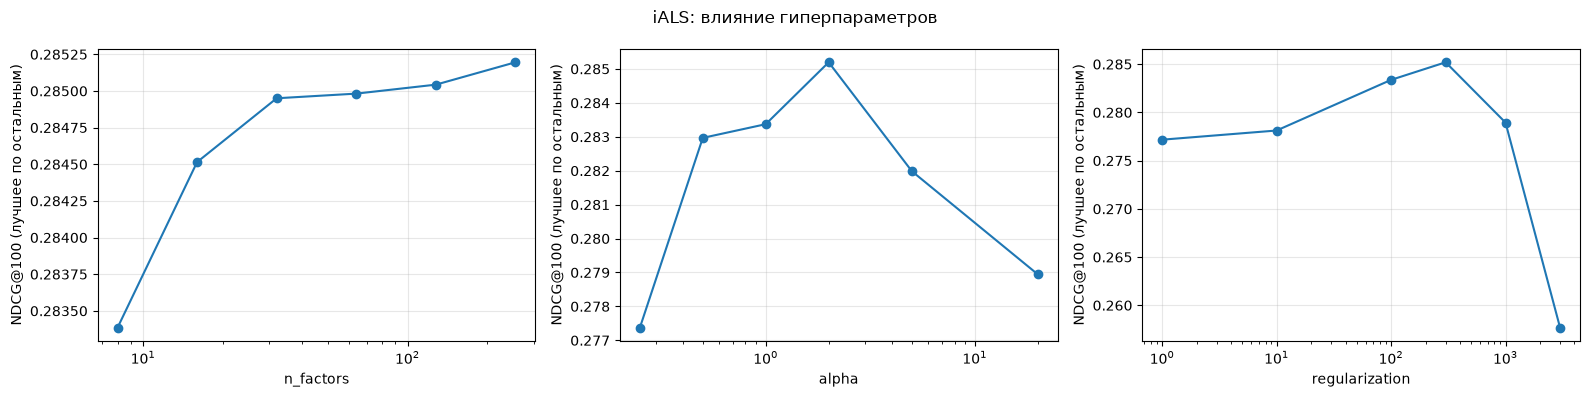

,ndcg@100,recall@100
TopPopular,0.250202,0.227404
SVD (k=10),0.275399,0.258378
"iALS (implicit, лучшие параметры)",0.285196,0.267529


In [26]:
best_als = als_grid.iloc[0]
best_als_params = dict(n_factors=int(best_als.n_factors), alpha=float(best_als.alpha), regularization=float(best_als.regularization))
print('Лучшие параметры iALS:', best_als_params, '| NDCG@100 = %.4f' % best_als['ndcg@100'])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, param in zip(axes, ['n_factors', 'alpha', 'regularization']):
    # для каждого значения параметра — лучший результат по остальным параметрам
    best_by_param = als_grid.groupby(param)['ndcg@100'].max()
    ax.plot(best_by_param.index, best_by_param.values, marker='o')
    ax.set_xscale('log'); ax.set_xlabel(param); ax.set_ylabel('NDCG@100 (лучшее по остальным)'); ax.grid(alpha=0.3)
plt.suptitle('iALS: влияние гиперпараметров'); plt.tight_layout(); plt.show()

als_recs, als_model = make_als_recommendations(coo_interactions, 100, return_model=True, **best_als_params)
svd_best_recs = make_svd_recommendations(coo_interactions, best_n_svd, 100, seen_mask=seen_mask_train)
compare = pd.DataFrame({
    'TopPopular': evaluate_recs(pop_recs),
    f'SVD (k={best_n_svd})': evaluate_recs(svd_best_recs),
    'iALS (implicit, лучшие параметры)': evaluate_recs(als_recs),
}).T
compare

**Выводы (3.1).**
* **Лучшая конфигурация.** Перебрали 6 × 6 × 6 = 216 комбинаций (число факторов × alpha × регуляризация). Лучшая — **256 факторов, alpha = 2, регуляризация 300**: NDCG@100 = 0.2852. Для сравнения: SVD с k = 10 — 0.2754, TopPopular — 0.2502.
* **Главный параметр — регуляризация.** Все лучшие конфигурации имеют λ = 100–300. При λ = 300 и alpha = 2 число факторов почти не влияет на качество: от 8 до 256 факторов NDCG@100 = 0.283–0.285.
* **alpha нужен небольшой (≈2).** В implicit доверие c = alpha · r. При больших alpha наблюдаемые пары сильно перевешивают «нули», и непросмотренное ранжируется хуже.
* **Оговорка.** Как и в формулировке задания, подбор шёл по тестовой выборке. Честнее выделить валидацию по времени из трейна — тогда оценка качества была бы чуть ниже.

##### Задание 3.2. Сделайте объяснение рекомендаций для нескольких юзеров(als.explain). Воспользуйтесь файлом movies.dat чтобы перейти от индексов фильмов к их названием

In [27]:
# Объяснение рекомендаций iALS: какие из просмотренных фильмов сильнее всего «тянут» рекомендацию
movies = pd.read_csv(os.path.join(DATA_DIR, 'movies.dat'), sep='::', engine='python',
                     names=['item_id', 'title', 'genres'], encoding='latin-1')
movie_title = dict(zip(movies.item_id, movies.title))
def title_of(encoded_item):
    return movie_title[item_le.inverse_transform([encoded_item])[0]]

user_items_csr = csr_matrix(coo_interactions, dtype=np.float32)
rng = np.random.default_rng(7)
for user in rng.choice(test_users, size=4, replace=False):
    print('=' * 100)
    liked = user_items_csr[user]
    top_watched = liked.indices[np.argsort(-liked.data)][:5]
    print(f'Пользователь {user} (оценил {liked.nnz} фильмов). Примеры высоко оценённых:',
          '; '.join(title_of(i) for i in top_watched))
    for item in als_recs[user][:2]:
        score, contributions, _ = als_model.explain(user, user_items_csr, item)   # explain сам берёт строку user_items[user]
        print(f'  -> рекомендация: {title_of(item)} (score = {score:.3f}). Главные причины:')
        for watched_item, contrib in contributions[:5]:
            print(f'       {contrib:+.3f}  {title_of(watched_item)}')

Пользователь 4909 (оценил 239 фильмов). Примеры высоко оценённых: Heat (1995); Dangerous Liaisons (1988); Exorcist, The (1973); Rocky (1976); French Connection, The (1971)
  -> рекомендация: Schindler's List (1993) (score = 1.034). Главные причины:
       +0.027  American Beauty (1999)
       +0.023  Silence of the Lambs, The (1991)
       +0.020  L.A. Confidential (1997)
       +0.019  Godfather, The (1972)
       +0.019  Being John Malkovich (1999)
  -> рекомендация: One Flew Over the Cuckoo's Nest (1975) (score = 0.978). Главные причины:
       +0.020  American Beauty (1999)
       +0.017  Godfather, The (1972)
       +0.016  Silence of the Lambs, The (1991)
       +0.015  L.A. Confidential (1997)
       +0.015  Godfather: Part II, The (1974)
Пользователь 2637 (оценил 448 фильмов). Примеры высоко оценённых: It's a Wonderful Life (1946); Psycho (1960); Galaxy Quest (1999); Die Hard (1988); Jurassic Park (1993)
  -> рекомендация: Godfather, The (1972) (score = 1.133). Главные причины:

**Выводы (3.2).** `explain` раскладывает скор рекомендации на вклады уже оценённых фильмов. Объяснения правдоподобны:
* Пользователю 4909 с классическими криминальными драмами (Heat, The French Connection) рекомендуются Schindler's List и One Flew Over the Cuckoo's Nest. Главные вклады — American Beauty, The Silence of the Lambs, L.A. Confidential, The Godfather.
* Пользователю 4628 с 21 оценкой (Being John Malkovich, American Beauty и др.) — Shakespeare in Love, и главный вклад дают те же American Beauty и Being John Malkovich.

Видно и ограничение. В объяснениях разных пользователей повторяются одни и те же «хабы» — American Beauty и The Silence of the Lambs: популярные фильмы с высокими оценками. При сильной регуляризации модель опирается на популярное ядро каталога, и рекомендации разных юзеров похожи.

##### Задание 4. До этого мы работали с рейтингами, но как обсуждалось на лекции, implicit ALS отлично работает и с implicit фидбэком. Давайте попробуем преобразовать наш датасет(трейн и тест) следующим образом

1. Бинаризуем все рейтинги(заменим любую интеракцию пользователя на 1)
2. Заменим на 1 только рейтинги 4 и 5, а рейтинг ниже 4 заменим на 0
3. Заменим на 1 только рейтинги 4 и 5, а рейтинг ниже 4 заменим на -1
4. Заменим на 1 только рейтинги 4 и 5, а рейтинг ниже 4 заменим на -1 и добавим сглаживание по времени. То есть чем дальше была интеракция от максимальной даты трейна, тем с меньшим весом мы будем ее учитывать(например можно интеракции за последний месяц брать в исходном виде, и с каждым месяцем в прошлое умножать их на какой-нибудь коэффициент меньший 1). Таким образом более старые интеракции пользователя будут вносить меньший вклад в его интересы
5. Придумайте свой вариант(опционально)

Для каждой полученной матрицы обучите iALS и SVD и сравните их результаты между собой(преобразовывать нужно только обучающую выборку, тестовую оставляем неизменной)

In [28]:
max_train_date = df_train['datetime'].max()

def make_train_variant(df: pd.DataFrame, kind: str, decay: float = 0.8) -> coo_array:
    d = df.copy()
    if kind == '1_binary':                 # любая интеракция -> 1
        d['rating'] = 1.0
    elif kind == '2_pos_only':             # 4 и 5 -> 1, ниже 4 -> 0
        d['rating'] = (d['rating'] >= 4).astype(float)
    elif kind == '3_pos_neg':              # 4 и 5 -> 1, ниже 4 -> -1
        d['rating'] = np.where(d['rating'] >= 4, 1.0, -1.0)
    elif kind == '4_pos_neg_time':         # как 3 + затухание по времени: x decay за каждый месяц до конца трейна
        months_ago = ((max_train_date - d['datetime']).dt.days // 30).values
        d['rating'] = np.where(d['rating'] >= 4, 1.0, -1.0) * decay ** months_ago
    elif kind == '5_centered':             # свой вариант: рейтинг минус средний рейтинг пользователя
        d['rating'] = d['rating'] - d.groupby('user_id')['rating'].transform('mean')
        d.loc[d['rating'] == 0, 'rating'] = 1e-3   # чтобы «средние» оценки не пропали из sparse-матрицы
    else:
        raise ValueError(kind)
    d = d[d['rating'] != 0]
    return df_to_coo(d)

months_ago = (max_train_date - df_train['datetime']).dt.days // 30
print('Распределение интеракций трейна по «месяцам назад»:')
print(months_ago.value_counts().sort_index().to_string())

Распределение интеракций трейна по «месяцам назад»:
datetime
0    289196
1     40378
2     52110
3    162084
4     89422
5     66901
6     68338
7     18991


In [29]:
%%time
variant_results = []
variants = ['0_raw_ratings', '1_binary', '2_pos_only', '3_pos_neg', '4_pos_neg_time', '5_centered']
for kind in tqdm(variants):
    matrix = coo_interactions if kind == '0_raw_ratings' else make_train_variant(df_train, kind)
    # SVD: перебираем число компонент, просмотренные фильмы фильтруем по исходному трейну
    svd_scores = []
    for n in [5, 10, 20, 50, 100]:
        recs = make_svd_recommendations(matrix, n, 100, seen_mask=seen_mask_train)
        svd_scores.append((evaluate_recs(recs)['ndcg@100'], n))
    best_svd_ndcg, best_svd_n = max(svd_scores)
    # iALS: масштаб значений у вариантов разный, поэтому для каждого заново подбираем alpha и регуляризацию
    # (число факторов фиксируем = 64: в задании 3.1 при сильной регуляризации оно почти не влияет на качество)
    als_scores = []
    for alpha in [0.5, 1, 2, 5, 10, 20]:
        for reg in [10, 30, 100, 300, 1000]:
            recs = make_als_recommendations(matrix, 100, 64, alpha, reg, seen_matrix=coo_interactions)
            als_scores.append((evaluate_recs(recs)['ndcg@100'], alpha, reg))
    best_als_ndcg, best_als_alpha, best_als_reg = max(als_scores)
    variant_results.append({'variant': kind, 'SVD ndcg@100': best_svd_ndcg, 'SVD best k': best_svd_n,
                            'iALS ndcg@100': best_als_ndcg, 'iALS best alpha': best_als_alpha, 'iALS best reg': best_als_reg})
variant_results = pd.DataFrame(variant_results).set_index('variant')
variant_results

  0%|          | 0/6 [00:00<?, ?it/s]

CPU times: user 5min 38s, sys: 2.11 s, total: 5min 40s
Wall time: 5min 40s


,SVD ndcg@100,SVD best k,iALS ndcg@100,iALS best alpha,iALS best reg
variant,,,,,
0_raw_ratings,0.275399,10,0.284982,2,300
1_binary,0.268912,5,0.279778,10,300
2_pos_only,0.277802,10,0.288477,20,300
3_pos_neg,0.257734,10,0.287063,5,100
4_pos_neg_time,0.261233,10,0.292571,5,100
5_centered,0.242573,10,0.284720,5,100


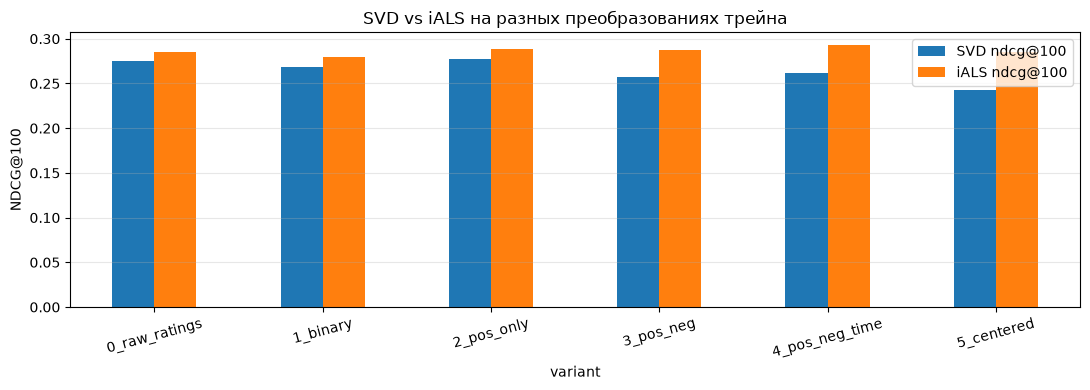

,decay,ndcg@100,recall@100
0,0.1,0.293694,0.287692
1,0.2,0.294851,0.288804
2,0.3,0.295780,0.289427
3,0.5,0.295658,0.288831
4,0.7,0.293945,0.283576
5,0.9,0.289659,0.277733
6,1.0,0.287063,0.275129


In [30]:
# Чувствительность варианта 4 к коэффициенту затухания
decay_res = []
for decay in [0.1, 0.2, 0.3, 0.5, 0.7, 0.9, 1.0]:
    matrix = make_train_variant(df_train, '4_pos_neg_time', decay=decay)
    recs = make_als_recommendations(matrix, 100, 64, variant_results.loc['4_pos_neg_time', 'iALS best alpha'],
                                    variant_results.loc['4_pos_neg_time', 'iALS best reg'], seen_matrix=coo_interactions)
    decay_res.append({'decay': decay, **evaluate_recs(recs)})
decay_res = pd.DataFrame(decay_res)

ax = variant_results[['SVD ndcg@100', 'iALS ndcg@100']].plot.bar(figsize=(11, 4), rot=15)
ax.set_ylabel('NDCG@100'); ax.set_title('SVD vs iALS на разных преобразованиях трейна'); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()
decay_res

**Выводы (задание 4).** Для каждого варианта подобраны число компонент SVD, а также alpha и регуляризация iALS.
* **iALS: лучший вариант — 4** (позитивы +1, негативы −1, затухание по времени). NDCG@100 = 0.2926 при затухании 0.8 в месяц и **0.2958** при лучшем затухании 0.3 — лучший результат в лабораторной. Остальные варианты:
  * без затухания (вариант 3) — 0.2871;
  * только позитивы (вариант 2) — 0.2885;
  * исходные рейтинги — 0.2850;
  * центрирование — 0.2847;
  * бинаризация — 0.2798.
* **Для iALS полезно две вещи:**
  1. Отделять понравившееся от не понравившегося. Бинаризация всех интеракций хуже всего: оценки ниже 4 — слабый или отрицательный сигнал.
  2. Давать больший вес свежим интеракциям: тест идёт сразу после трейна, и недавние вкусы предсказывают его лучше. Затухание от 0.1 до 0.5 в месяц работает почти одинаково хорошо, без затухания хуже.
* **SVD реагирует иначе.** Лучший вариант — 2, только позитивы: 0.2778 против 0.2754 на исходных рейтингах. Отрицательные значения (варианты 3–5) SVD ухудшают: 0.243–0.261. SVD приближает саму матрицу в смысле MSE, и −1 у не понравившегося фильма тянет вниз скоры похожих фильмов, хотя сам факт просмотра говорит об интересе к ним. iALS трактует отрицательное значение как уверенность в «не нравится» отдельно от предпочтения, поэтому ему −1 не вредит.
* **Свой вариант 5** (рейтинг минус средний рейтинг пользователя) не помог ни SVD, ни iALS. Центрирование стирает главный для top-k сигнал «пользователь посмотрел этот фильм».

##### Задание 5. iALS на numpy/torch. Давайте реализуем алгоритм iALS на нумпае или торче. Требуется реализовать алгорит, описанный в 4 части [статьи](http://yifanhu.net/PUB/cf.pdf). Обратите внимания на все оптимизации, которые они описывают в статье, чтобы сократить лишние вычисления. Hint: метрики у вашего алгоритма должны быть сравнимы с метриками ALS из библиотеки implicit

In [31]:
class iALS:
    """Implicit ALS по Hu, Koren, Volinsky (2008), раздел 4.
    c_ui = 1 + alpha * r_ui, p_ui = [r_ui > 0].
    Оптимизации из статьи: Y^T C^u Y = Y^T Y + Y^T (C^u - I) Y, где Y^T Y считается один раз на шаг,
    а второе слагаемое и Y^T C^u p(u) — только по n_u ненулевым айтемам пользователя: O(f^2 n_u + f^3) на юзера."""

    def __init__(self, n_factors: int = 100, alpha: float = 1.0, reg_coef = 0.01, random_state: int = 42):
        self.n_factors = n_factors
        self.alpha = alpha
        self.reg_coef = reg_coef
        self.rng = np.random.default_rng(random_state)
        self.loss_history = []

    def _solve(self, Cm1: csr_matrix, fixed: np.ndarray) -> np.ndarray:
        """Одна половина шага ALS: Cm1 — sparse-матрица (C - I) для оптимизируемой стороны, fixed — зафиксированные векторы."""
        f = self.n_factors
        YtY = fixed.T @ fixed
        reg_I = self.reg_coef * np.eye(f)
        result = np.zeros((Cm1.shape[0], f))
        indptr, indices, data = Cm1.indptr, Cm1.indices, Cm1.data
        for u in range(Cm1.shape[0]):
            start, end = indptr[u], indptr[u + 1]
            if start == end:
                continue                               # нет интеракций -> нулевой вектор
            idx, cm1 = indices[start:end], data[start:end]
            Yu = fixed[idx]                            # [n_u, f]
            A = YtY + (Yu.T * cm1) @ Yu + reg_I       # Y^T C^u Y + lambda I
            b = Yu.T @ (1.0 + cm1)                     # Y^T C^u p(u), p_ui = 1 только для ненулевых
            result[u] = np.linalg.solve(A, b)
        return result

    def _loss(self) -> float:
        # полная функция потерь (матрица небольшая, можно посчитать честно)
        pred = self.X @ self.Y.T
        P = np.zeros_like(pred); C = np.ones_like(pred)
        rows, cols = self.R.nonzero()
        P[rows, cols] = 1.0
        C[rows, cols] = 1.0 + self.alpha * np.asarray(self.R[rows, cols]).ravel()
        return float((C * (P - pred) ** 2).sum() + self.reg_coef * ((self.X ** 2).sum() + (self.Y ** 2).sum()))

    def fit(self, interractions: np.ndarray, n_iterations: int = 10, track_loss: bool = True):
        self.R = csr_matrix(interractions, dtype=np.float64)
        self.R.eliminate_zeros()
        n_users, n_items = self.R.shape
        Cm1_users = self.R.multiply(self.alpha).tocsr()        # (C - I) по строкам-пользователям
        Cm1_items = Cm1_users.T.tocsr()                        # (C - I) по строкам-айтемам
        self.X = self.rng.normal(0, 0.01, (n_users, self.n_factors))
        self.Y = self.rng.normal(0, 0.01, (n_items, self.n_factors))
        for it in range(n_iterations):
            self.X = self._solve(Cm1_users, self.Y)
            self.Y = self._solve(Cm1_items, self.X)
            if track_loss:
                self.loss_history.append(self._loss())
        return self

    def predict(self, top_k: int = 100):
        # возвращает top-k айтемов для каждого юзера(айтемы с которыми юзер взаимодействовал не должны попасть в рекомендации)
        scores = self.X @ self.Y.T
        seen_mask = self.R.toarray() != 0
        predicts = top_k_from_scores(scores, seen_mask, top_k)
        return predicts # shape ~ [n_users, top_k]

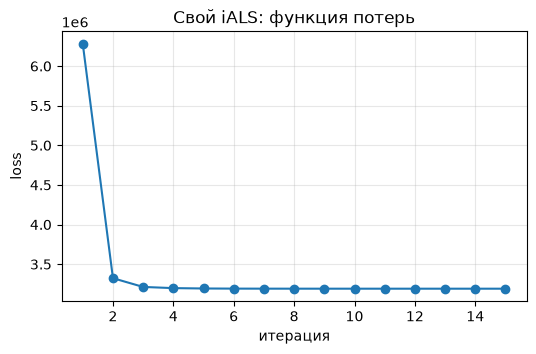

CPU times: user 55.2 s, sys: 617 ms, total: 55.8 s
Wall time: 53.7 s


,ndcg@100,recall@100,"время, с"
"iALS (своя реализация, numpy)",0.285286,0.269160,44.573585
iALS (implicit),0.285196,0.267529,8.860985


In [32]:
%%time
# Сравним свою реализацию с implicit на одинаковых данных и гиперпараметрах.
# В implicit доверие c_ui = alpha * r_ui, у нас (как в статье) c_ui = 1 + alpha * r_ui.
start = time.perf_counter()
my_ials = iALS(n_factors=best_als_params['n_factors'], alpha=best_als_params['alpha'],
               reg_coef=best_als_params['regularization']).fit(coo_interactions, n_iterations=15)
my_time = time.perf_counter() - start
my_recs = my_ials.predict(top_k=100)

start = time.perf_counter()
lib_recs = make_als_recommendations(coo_interactions, 100, **best_als_params)
lib_time = time.perf_counter() - start

plt.figure(figsize=(6, 3.5))
plt.plot(range(1, len(my_ials.loss_history) + 1), my_ials.loss_history, marker='o')
plt.xlabel('итерация'); plt.ylabel('loss'); plt.title('Свой iALS: функция потерь'); plt.grid(alpha=0.3); plt.show()

pd.DataFrame({
    'iALS (своя реализация, numpy)': {**evaluate_recs(my_recs), 'время, с': my_time},
    'iALS (implicit)': {**evaluate_recs(lib_recs), 'время, с': lib_time},
}).T

**Выводы (задание 5).**
* **Как реализовано.** Своя реализация iALS повторяет раздел 4 статьи Hu, Koren, Volinsky: YᵀY считается один раз на полушаг, а поправка Yᵀ(Cᵘ − I)Y и правая часть — только по n_u оценённым айтемам юзера.
* **Качество совпадает с implicit**: NDCG@100 = 0.2853 против 0.2852 при тех же гиперпараметрах (256 факторов, alpha = 2, λ = 300). Функция потерь монотонно убывает.
* **По времени своя версия медленнее**: ≈45 с против ≈9 с у implicit. У нас цикл по юзерам на Python и решение системы 256 × 256 в numpy, а в implicit — нативный код и метод сопряжённых градиентов.
* **Масштаб alpha у нас другой**: c = 1 + alpha · r против c = alpha · r в implicit. Тем не менее оптимум совпал — alpha ≈ 2 (NDCG@100 = 0.2856).

In [33]:
# Для своей реализации alpha в другом масштабе (из-за «1 +» в доверии) — небольшая проверка соседних значений
my_alpha = []
for alpha in [0.05, 0.1, 0.25, 0.5, 1, 2, 5, 20]:
    model = iALS(n_factors=best_als_params['n_factors'], alpha=alpha,
                 reg_coef=best_als_params['regularization']).fit(coo_interactions, n_iterations=10, track_loss=False)
    my_alpha.append({'alpha': alpha, **evaluate_recs(model.predict(100))})
pd.DataFrame(my_alpha)

,alpha,ndcg@100,recall@100
0,0.05,0.238617,0.206675
1,0.10,0.240097,0.208685
2,0.25,0.242761,0.212604
3,0.50,0.253264,0.223949
4,1.00,0.275492,0.252560
5,2.00,0.285613,0.269536
6,5.00,0.278661,0.273761
7,20.00,0.252742,0.258097
